# Car Price Prediction with Machine Learning

**Goal:** predict the selling price of a used vehicle from its features (present price, age, kilometres driven, fuel type, transmission, seller type, owner count and brand), and understand which features drive the price.

**Workflow:** inspect -> clean -> feature engineering -> EDA -> model comparison (cross-validation) -> tuning -> hold-out evaluation -> error analysis -> feature importance -> prediction helper.

**Data:** `data/car_data.csv`, 301 rows, one row per listing.

| Column | Meaning |
|---|---|
| Car_Name | model name (e.g. `ritz`, `fortuner`, `Bajaj Pulsar 150`) |
| Year | year of manufacture |
| Selling_Price | **target**: price the vehicle sold for |
| Present_Price | current showroom price of the same model when new |
| Driven_kms | kilometres driven |
| Fuel_Type | Petrol / Diesel / CNG |
| Selling_type | Dealer / Individual |
| Transmission | Manual / Automatic |
| Owner | number of previous owners |

Prices are assumed to be in **lakh INR** (1 lakh = 100,000 INR), the usual unit for this dataset. Numbers in the text below come from one run; a rerun with different library versions can change them slightly.

## 1. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, RepeatedKFold, ShuffleSplit,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df_raw = pd.read_csv(ROOT / "data" / "car_data.csv")
print("Project folder:", ROOT)
print("Shape:", df_raw.shape)
df_raw.head()

Project folder: /home/claude/car-price-prediction
Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 2. Inspect the raw data

Cleaning should be driven by evidence, so we look for problems first.

In [2]:
print(df_raw.dtypes)
print("\nMissing values:", int(df_raw.isnull().sum().sum()))
print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
print("Car names with stray whitespace:", int((df_raw["Car_Name"] != df_raw["Car_Name"].str.strip()).sum()))
df_raw.describe().T.round(2)

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type            str
Selling_type         str
Transmission         str
Owner              int64
dtype: object

Missing values: 0
Exact duplicate rows: 2
Car names with stray whitespace: 5


,count,mean,std,min,25%,50%,75%,max
Year,301.0,2013.63,2.89,2003.00,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,4.66,5.08,0.10,0.9,3.6,6.0,35.0
Present_Price,301.0,7.63,8.64,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,36947.21,38886.88,500.00,15000.0,32000.0,48767.0,500000.0
Owner,301.0,0.04,0.25,0.00,0.0,0.0,0.0,3.0


In [3]:
for col in ["Fuel_Type", "Selling_type", "Transmission", "Owner"]:
    print(col, df_raw[col].value_counts().to_dict())
print("Distinct car names:", df_raw["Car_Name"].nunique())

Fuel_Type {'Petrol': 239, 'Diesel': 60, 'CNG': 2}
Selling_type {'Dealer': 195, 'Individual': 106}
Transmission {'Manual': 261, 'Automatic': 40}
Owner {0: 290, 1: 10, 3: 1}
Distinct car names: 98


**What the inspection shows**
- No missing values, but **2 exact duplicate rows** (same model, year, price and kilometres).
- The dataset has **no horsepower column and no brand column**. "Mileage" is available only as kilometres driven. The brand has to be derived from the car name.
- `Car_Name` mixes **cars and motorcycles/scooters** (`Activa 3g`, `Bajaj Pulsar 150`, `Royal Enfield Classic 350`). Their prices are about ten times lower, so vehicle type is an important feature.
- Very skewed numbers: a few expensive cars (Land Cruiser 35, Fortuner 33), and one vehicle with 500,000 km.

## 3. Clean

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
df["Car_Name"] = df["Car_Name"].str.strip()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 299


Outliers (Land Cruiser at 35, 500,000 km) are **kept**: they are real listings, not errors, and removing the expensive cars would hide the part of the market where prediction is hardest.

## 4. Feature engineering

1. **`car_age`** = newest year in the data minus the manufacture year. Age is more meaningful to a price model than a calendar year, and it does not depend on today's date.
2. **`brand`** and **`vehicle_type`** are derived from `Car_Name` with a small lookup (the task asks for "brand goodwill"; the dataset has no brand column).
3. Brands with fewer than 5 rows are grouped into `Other`, so the model does not memorise single listings.

Categorical columns are one-hot encoded **inside the model pipeline**, so no information from the test data leaks into training.

In [5]:
CAR_BRANDS = {
    "800": "Maruti Suzuki", "alto 800": "Maruti Suzuki", "alto k10": "Maruti Suzuki", "ertiga": "Maruti Suzuki",
    "ciaz": "Maruti Suzuki", "dzire": "Maruti Suzuki", "ignis": "Maruti Suzuki", "baleno": "Maruti Suzuki",
    "ritz": "Maruti Suzuki", "s cross": "Maruti Suzuki", "swift": "Maruti Suzuki", "sx4": "Maruti Suzuki",
    "vitara brezza": "Maruti Suzuki", "wagon r": "Maruti Suzuki", "omni": "Maruti Suzuki",
    "amaze": "Honda", "brio": "Honda", "city": "Honda", "jazz": "Honda",
    "camry": "Toyota", "corolla": "Toyota", "corolla altis": "Toyota", "etios cross": "Toyota",
    "etios g": "Toyota", "etios gd": "Toyota", "etios liva": "Toyota", "fortuner": "Toyota",
    "innova": "Toyota", "land cruiser": "Toyota",
    "creta": "Hyundai", "elantra": "Hyundai", "eon": "Hyundai", "grand i10": "Hyundai", "i10": "Hyundai",
    "i20": "Hyundai", "verna": "Hyundai", "xcent": "Hyundai",
}
# Two-wheeler keywords, checked in order ("hero honda" must match Hero before Honda)
TWO_WHEELER_KEYS = [("hero", "Hero"), ("honda", "Honda"), ("activa", "Honda"), ("bajaj", "Bajaj"),
                    ("ktm", "KTM"), ("royal enfield", "Royal Enfield"), ("tvs", "TVS"), ("yamaha", "Yamaha"),
                    ("suzuki", "Suzuki"), ("mahindra", "Mahindra"), ("um ", "UM"), ("hyosung", "Hyosung")]

def brand_of(name):
    n = " ".join(name.lower().split())
    if n in CAR_BRANDS:
        return CAR_BRANDS[n], "car"
    for key, brand in TWO_WHEELER_KEYS:
        if key in n:
            return brand, "two_wheeler"
    return "Other", "unknown"

parsed = df["Car_Name"].apply(brand_of)
df["brand"] = [b for b, _ in parsed]
df["vehicle_type"] = [t for _, t in parsed]
assert (df["vehicle_type"] != "unknown").all(), "some car names were not mapped"

REF_YEAR = df["Year"].max()
df["car_age"] = REF_YEAR - df["Year"]

brand_counts = df["brand"].value_counts()
df["brand"] = df["brand"].where(df["brand"].map(brand_counts) >= 5, "Other")
KNOWN_BRANDS = set(df["brand"])

print(df["vehicle_type"].value_counts().to_dict())
print(df["brand"].value_counts().to_dict())
df[["Car_Name", "Year", "car_age", "brand", "vehicle_type", "Selling_Price"]].sample(6, random_state=1)

{'car': 198, 'two_wheeler': 101}
{'Honda': 70, 'Hyundai': 50, 'Maruti Suzuki': 49, 'Toyota': 49, 'Bajaj': 25, 'Royal Enfield': 17, 'Hero': 15, 'Other': 8, 'Yamaha': 8, 'TVS': 8}


,Car_Name,Year,car_age,brand,vehicle_type,Selling_Price
173,Hero Honda CBZ extreme,2011,7,Hero,two_wheeler,0.38
287,city,2016,2,Honda,car,10.11
51,innova,2017,1,Toyota,car,18.00
146,Bajaj Pulsar 220 F,2010,8,Bajaj,two_wheeler,0.52
214,eon,2016,2,Hyundai,car,2.90
197,Honda CB Shine,2007,11,Honda,two_wheeler,0.12


## 5. Exploratory analysis

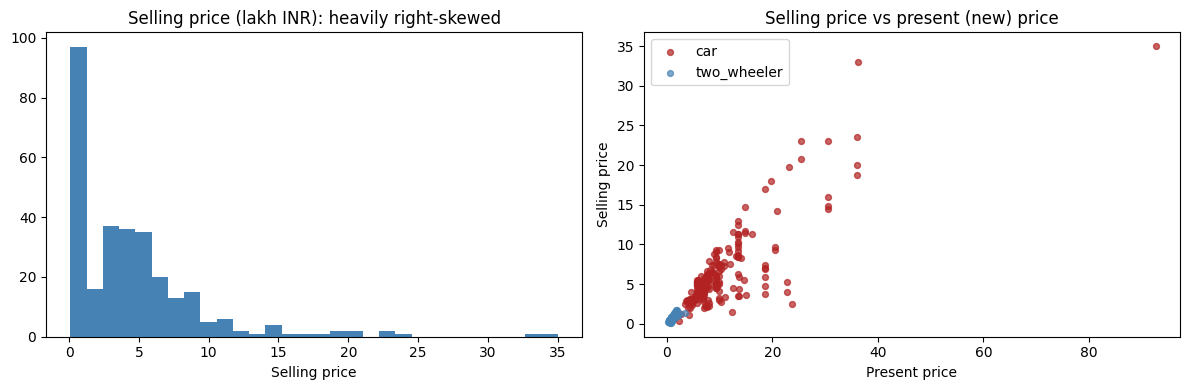

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["Selling_Price"], bins=30, color="steelblue")
ax[0].set_title("Selling price (lakh INR): heavily right-skewed")
ax[0].set_xlabel("Selling price")
colors = {"car": "firebrick", "two_wheeler": "steelblue"}
for vt, grp in df.groupby("vehicle_type"):
    ax[1].scatter(grp["Present_Price"], grp["Selling_Price"], s=18, alpha=0.7, label=vt, color=colors[vt])
ax[1].set_title("Selling price vs present (new) price")
ax[1].set_xlabel("Present price"); ax[1].set_ylabel("Selling price"); ax[1].legend()
plt.tight_layout(); plt.show()

         count  median
car_age               
0-2 yrs     50    0.82
3-5 yrs     93    0.66
6-8 yrs     39    0.47
9+ yrs      16    0.26


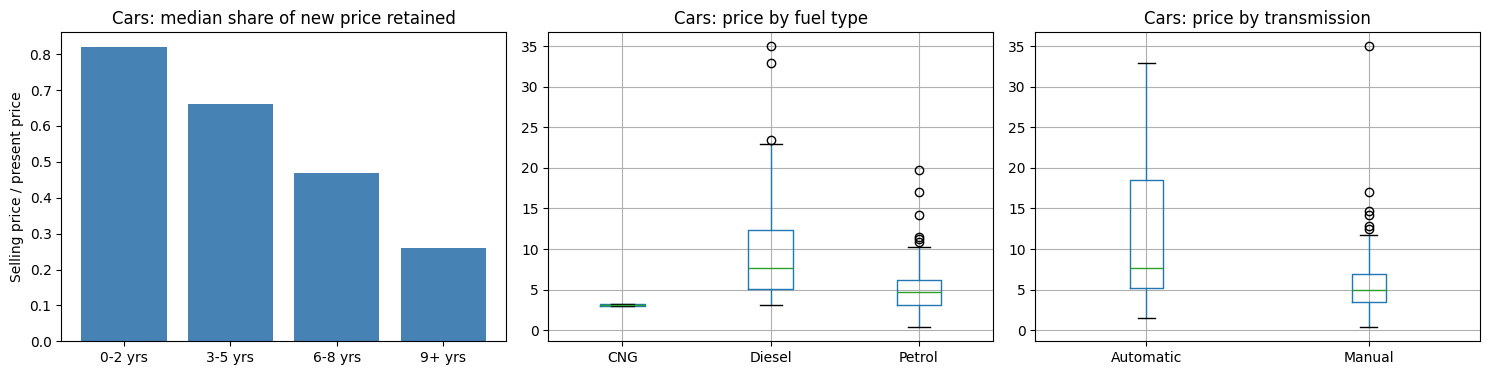

In [7]:
cars = df[df["vehicle_type"] == "car"].copy()
cars["retained"] = cars["Selling_Price"] / cars["Present_Price"]     # share of the new price still held
age_band = pd.cut(cars["car_age"], bins=[-1, 2, 5, 8, 20], labels=["0-2 yrs", "3-5 yrs", "6-8 yrs", "9+ yrs"])
retained = cars.groupby(age_band, observed=True)["retained"].agg(["count", "median"]).round(2)
print(retained)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(retained.index.astype(str), retained["median"], color="steelblue")
ax[0].set_title("Cars: median share of new price retained"); ax[0].set_ylabel("Selling price / present price")
cars.boxplot(column="Selling_Price", by="Fuel_Type", ax=ax[1]); ax[1].set_title("Cars: price by fuel type")
cars.boxplot(column="Selling_Price", by="Transmission", ax=ax[2]); ax[2].set_title("Cars: price by transmission")
for a in ax[1:]: a.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

In [8]:
df[["Selling_Price", "Present_Price", "Driven_kms", "car_age", "Owner"]].corr().round(2)

,Selling_Price,Present_Price,Driven_kms,car_age,Owner
Selling_Price,1.00,0.88,0.03,-0.23,-0.09
Present_Price,0.88,1.00,0.21,0.05,0.01
Driven_kms,0.03,0.21,1.00,0.53,0.09
car_age,-0.23,0.05,0.53,1.00,0.18
Owner,-0.09,0.01,0.09,0.18,1.00


**What the exploration shows**
- Prices are heavily skewed: 36% of the vehicles sell below 2 lakh, while only 12 sell above 15 lakh. Those few expensive vehicles are the hardest part of the market to predict.
- `Present_Price` has by far the strongest link with `Selling_Price` (correlation 0.88). `car_age` is moderately negative (-0.23). `Driven_kms` looks almost unrelated (0.03) because the dataset mixes cars and motorcycles; kilometres and age are also correlated with each other (0.53).
- Depreciation is clear for cars: the median car keeps about 82% of its new price at 0-2 years, 66% at 3-5 years, 47% at 6-8 years and 26% at 9+ years.
- Diesel and automatic cars sell for more in the box plots, but they are also the more expensive models (Fortuner, Innova). This does not prove that fuel type or transmission *causes* a higher price. The feature importance in section 9 checks this.

## 6. Model comparison

The dataset is small (299 rows), so a single train/test split is noisy. The plan:
1. Keep **20%** of the data as a final hold-out test set that is not touched until the end.
2. Compare models with **repeated 5-fold cross-validation** on the remaining 80%.
3. Tune the best tree models, then evaluate once on the hold-out set.

Models: Linear Regression and Ridge (need scaled numbers), Random Forest and Gradient Boosting (do not need scaling).

In [9]:
NUM = ["Present_Price", "Driven_kms", "Owner", "car_age"]
CAT = ["Fuel_Type", "Selling_type", "Transmission", "brand", "vehicle_type"]
X, y = df[NUM + CAT], df["Selling_Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape)

def make_pipe(model, scale):
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])
    return Pipeline([("prep", pre), ("model", model)])

candidates = {
    "Linear Regression": make_pipe(LinearRegression(), scale=True),
    "Ridge": make_pipe(Ridge(alpha=1.0), scale=True),
    "Random Forest": make_pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE), scale=False),
    "Gradient Boosting": make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
}

cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = {}
for name, pipe in candidates.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    rows[name] = {"R2": s["test_r2"].mean(), "MAE": -s["test_neg_mean_absolute_error"].mean(),
                  "RMSE": -s["test_neg_root_mean_squared_error"].mean()}

baseline_mae = mean_absolute_error(y_train, np.full(len(y_train), y_train.mean()))
cv_table = pd.DataFrame(rows).T.sort_values("MAE").round(3)
print("Baseline (always predict the mean price): MAE =", round(baseline_mae, 3))
cv_table

train: (239, 9) | test: (60, 9)


Baseline (always predict the mean price): MAE = 3.385


,R2,MAE,RMSE
Random Forest,0.890,0.671,1.512
Gradient Boosting,0.877,0.684,1.579
Ridge,0.863,1.150,1.784
Linear Regression,0.859,1.170,1.810


**Result:** the two tree models are clearly better than the linear models. Random Forest and Gradient Boosting have a mean absolute error of about 0.67-0.68 lakh (about Rs 67,000-68,000), against about 1.15-1.17 lakh for Ridge and Linear Regression. Always predicting the mean price gives an error of 3.4 lakh.

**Why trees win here:** a vehicle keeps a *percentage* of its new price, and that percentage depends on age. That is a multiplicative relationship with interactions (price x age), which a straight-line model cannot represent well, while trees can. Random Forest and Gradient Boosting are close to each other; the difference is too small to call a winner.

### Does feature engineering help?

Same Random Forest and the same cross-validation, with feature groups added one step at a time.

In [10]:
steps = [
    ("raw columns (Year instead of age)", ["Present_Price", "Driven_kms", "Owner", "Year"], ["Fuel_Type", "Selling_type", "Transmission"]),
    ("+ car_age instead of Year",         ["Present_Price", "Driven_kms", "Owner", "car_age"], ["Fuel_Type", "Selling_type", "Transmission"]),
    ("+ vehicle_type",                    NUM, ["Fuel_Type", "Selling_type", "Transmission", "vehicle_type"]),
    ("+ brand",                           NUM, CAT),
]
ab = {}
for label, num_cols, cat_cols in steps:
    pipe = Pipeline([
        ("prep", ColumnTransformer([("num", "passthrough", num_cols),
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])),
        ("model", RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE)),
    ])
    s = cross_validate(pipe, df.loc[X_train.index, num_cols + cat_cols], y_train, cv=cv, scoring="neg_mean_absolute_error")
    ab[label] = -s["test_score"].mean()
pd.Series(ab, name="CV MAE").round(3).to_frame()

,CV MAE
raw columns (Year instead of age),0.672
+ car_age instead of Year,0.675
+ vehicle_type,0.678
+ brand,0.671


**Honest result:** the engineered features did **not** measurably improve accuracy. The cross-validated error stays at about 0.67 lakh in every row (0.672, 0.675, 0.678, 0.671); differences of 0.007 lakh are within noise.

Reasons: `car_age` is just `Year` shifted (trees are not affected by that); `Present_Price` already tells the model whether the vehicle is a cheap motorcycle or an expensive car; and the brand's market position is already reflected in the new price. The features are still kept because `car_age` is easier to interpret and use, and the task asks for brand information, but they are not what makes the model accurate.

## 7. Hyperparameter tuning

In [11]:
inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gb_search = GridSearchCV(
    make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE), scale=False),
    {"model__n_estimators": [100, 200, 400], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.05, 0.1]},
    cv=inner_cv, scoring="neg_mean_absolute_error").fit(X_train, y_train)

rf_search = GridSearchCV(
    make_pipe(RandomForestRegressor(random_state=RANDOM_STATE), scale=False),
    {"model__n_estimators": [200, 400], "model__max_depth": [None, 6, 10], "model__min_samples_leaf": [1, 2, 4]},
    cv=inner_cv, scoring="neg_mean_absolute_error").fit(X_train, y_train)

print("Gradient Boosting best:", gb_search.best_params_, "| CV MAE", round(-gb_search.best_score_, 3))
print("Random Forest best:    ", rf_search.best_params_, "| CV MAE", round(-rf_search.best_score_, 3))

best_search = gb_search if gb_search.best_score_ >= rf_search.best_score_ else rf_search
final_name = "Gradient Boosting (tuned)" if best_search is gb_search else "Random Forest (tuned)"
final_model = best_search.best_estimator_
print("\nSelected model:", final_name)

Gradient Boosting best: {'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__n_estimators': 100} | CV MAE 0.669
Random Forest best:     {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 400} | CV MAE 0.675

Selected model: Gradient Boosting (tuned)


Tuning changed very little. The best Gradient Boosting (cross-validated error 0.669 lakh) and the best Random Forest (0.675 lakh) are practically tied. Gradient Boosting was selected only because its score is slightly lower, not because it is clearly better.

## 8. Final evaluation on the hold-out test set

The test set was not used for any choice so far.

{'R2': 0.823, 'MAE': 1.011, 'RMSE': 2.136}
Baseline MAE on the test set: 3.327


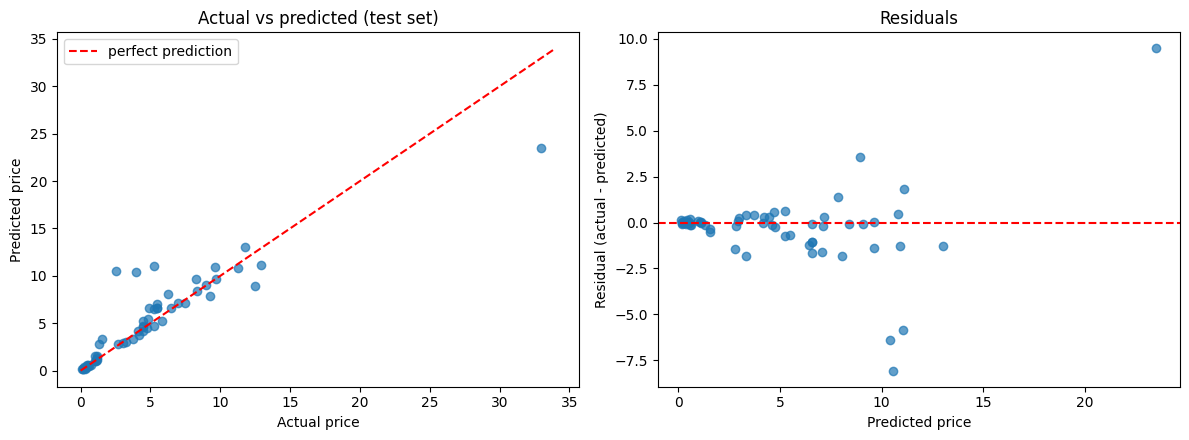

In [12]:
pred = final_model.predict(X_test)
test_scores = {"R2": r2_score(y_test, pred), "MAE": mean_absolute_error(y_test, pred),
               "RMSE": mean_squared_error(y_test, pred) ** 0.5}
print({k: round(v, 3) for k, v in test_scores.items()})
print("Baseline MAE on the test set:", round(mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())), 3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=0.7)
lim = [0, max(y_test.max(), pred.max()) + 1]
ax[0].plot(lim, lim, "r--", label="perfect prediction")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title("Actual vs predicted (test set)"); ax[0].legend()
ax[1].scatter(pred, y_test - pred, alpha=0.7)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted price"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

### Where does the model go wrong?

In [13]:
errors = X_test.copy()
errors["Car"] = df.loc[X_test.index, "Car_Name"]
errors["actual"], errors["predicted"] = y_test, pred
errors["abs_error"] = (errors["actual"] - errors["predicted"]).abs()
errors.sort_values("abs_error", ascending=False).head(5)[
    ["Car", "car_age", "Present_Price", "Driven_kms", "actual", "predicted", "abs_error"]].round(2)

,Car,car_age,Present_Price,Driven_kms,actual,predicted,abs_error
63,fortuner,1,36.23,6000,33.00,23.52,9.48
84,camry,12,23.73,142000,2.50,10.56,8.06
92,corolla altis,10,22.78,89000,4.00,10.40,6.40
77,corolla altis,8,22.83,80000,5.25,11.08,5.83
82,innova,3,13.46,38000,12.50,8.95,3.55


In [14]:
sq_err = (errors["actual"] - errors["predicted"]) ** 2
top5_share = sq_err.sort_values(ascending=False).head(5).sum() / sq_err.sum()
print(f"The 5 worst predictions account for {top5_share:.0%} of the total squared error ({len(sq_err)} test cars).")

bands = pd.cut(errors["actual"], bins=[0, 2, 6, 15, 100], labels=["< 2", "2-6", "6-15", "> 15"])
errors.groupby(bands, observed=True)["abs_error"].agg(["count", "mean"]).round(2).rename(
    columns={"count": "n cars", "mean": "mean abs error"})

The 5 worst predictions account for 88% of the total squared error (60 test cars).


,n cars,mean abs error
actual,,
< 2,23,0.24
2-6,22,1.45
6-15,14,0.98
> 15,1,9.48


**Result on the hold-out set:** R2 = 0.823 and mean absolute error = 1.01 lakh, against 3.33 lakh for always predicting the mean. The error is higher than in cross-validation (about 0.67 lakh), and the reason is visible in the tables above:

- **A handful of vehicles cause most of the error.** The 5 worst predictions account for 88% of the total squared error among the 60 test vehicles.
- **The worst cases are expensive vehicles.** The only car above 15 lakh in the test set (a Fortuner sold at 33 lakh) was predicted at 23.5 lakh. A 12-year-old Camry with 142,000 km sold at 2.5 lakh and was predicted at 10.6 lakh, and two 8-10-year-old Corolla Altis cars were overpredicted by 5.8 to 6.4 lakh. The model learned that "high new price means high resale price", but there are very few old, expensive cars in the training data to teach it how steeply they lose value.
- **Cheap vehicles are predicted well.** Vehicles under 2 lakh (23 of 60) have a mean error of only 0.24 lakh.

### How stable is the score?

With about 12 expensive vehicles in the whole dataset, a single split can look better or worse by luck. The same tuned model is re-evaluated on 20 different random 80/20 splits.

In [15]:
r2s, maes = [], []
for tr, te in ShuffleSplit(n_splits=20, test_size=0.2, random_state=0).split(X):
    m = final_model.fit(X.iloc[tr], y.iloc[tr])
    p = m.predict(X.iloc[te])
    r2s.append(r2_score(y.iloc[te], p)); maes.append(mean_absolute_error(y.iloc[te], p))
print(f"R2 : mean {np.mean(r2s):.3f} | min {np.min(r2s):.3f} | max {np.max(r2s):.3f}")
print(f"MAE: mean {np.mean(maes):.3f} | min {np.min(maes):.3f} | max {np.max(maes):.3f}")
final_model.fit(X_train, y_train);   # restore: fitted on the training set only

R2 : mean 0.928 | min 0.778 | max 0.972
MAE: mean 0.575 | min 0.391 | max 0.871


Across 20 random splits the score is much better and much more variable: R2 averages 0.928 (range 0.778 to 0.972) and the mean absolute error averages 0.575 lakh (range 0.391 to 0.871). The fixed split used above (error 1.01 lakh) is harder than all 20 of these, because it happens to contain the Fortuner, the Camry and the Corolla cars together.

These 20-split numbers are slightly optimistic, because the tuning used part of the same data. A realistic expectation is a typical error of roughly 0.6-0.7 lakh, and much larger errors for rare, expensive and old cars.

## 9. Which features matter?

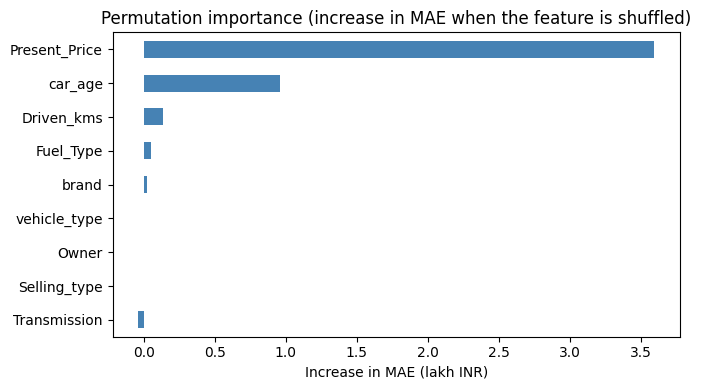

Present_Price    3.596
car_age          0.956
Driven_kms       0.133
Fuel_Type        0.052
brand            0.025
vehicle_type     0.003
Owner            0.000
Selling_type    -0.000
Transmission    -0.038
dtype: float64

In [16]:
imp = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE,
                             scoring="neg_mean_absolute_error")
imp_df = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
imp_df.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Permutation importance (increase in MAE when the feature is shuffled)")
plt.xlabel("Increase in MAE (lakh INR)"); plt.tight_layout(); plt.show()
imp_df.sort_values(ascending=False).round(3)

**Result:** `Present_Price` dominates (shuffling it raises the error by about 3.6 lakh), followed by `car_age` (about 1.0 lakh). Kilometres driven matters a little (0.13), fuel type, brand and vehicle type hardly matter, and owner count, seller type and transmission have no useful effect (transmission is slightly negative, which means noise).

**Caveats**
- Brand and vehicle type score low partly because `Present_Price` already contains most of that information, and permutation importance understates features that are correlated with a stronger one. The "brand goodwill" effect is largely captured through the new price.
- In practice the model needs the *new price of that exact model* as an input, so a real application would look it up from a price list.
- The box-plot gaps for diesel and automatic cars mostly vanish once the new price is known, which supports the earlier warning against reading them as causal.

## 10. Predict the price of a new vehicle

In [17]:
def predict_price(car_name, year, present_price, driven_kms, fuel, seller, transmission, owner=0):
    brand, vtype = brand_of(car_name)
    if brand not in KNOWN_BRANDS:
        brand = "Other"
    row = pd.DataFrame([{
        "Present_Price": present_price, "Driven_kms": driven_kms, "Owner": owner, "car_age": REF_YEAR - year,
        "Fuel_Type": fuel, "Selling_type": seller, "Transmission": transmission,
        "brand": brand, "vehicle_type": vtype,
    }])
    return float(final_model.predict(row)[0])

print("2015 Honda City, new price 10 lakh, 50,000 km, petrol, dealer, manual:")
print("  predicted selling price:", round(predict_price("city", 2015, 10.0, 50000, "Petrol", "Dealer", "Manual"), 2), "lakh")
print("2012 Maruti Swift, new price 6 lakh, 80,000 km, diesel, individual, manual:")
print("  predicted selling price:", round(predict_price("swift", 2012, 6.0, 80000, "Diesel", "Individual", "Manual"), 2), "lakh")

2015 Honda City, new price 10 lakh, 50,000 km, petrol, dealer, manual:
  predicted selling price: 6.92 lakh
2012 Maruti Swift, new price 6 lakh, 80,000 km, diesel, individual, manual:
  predicted selling price: 3.03 lakh


## 11. Conclusions, limitations and next steps

**Conclusions**
- A tree-based model predicts used-vehicle prices with a typical error of about 0.6-0.7 lakh, compared with 3.4 lakh for a naive guess. The main drivers are the new price and the age of the vehicle.
- Tree models beat linear models because depreciation is a percentage that changes with age.
- Feature engineering and tuning added little; the data itself (new price and age) carries most of the signal.

**Real-world use:** a dealer or an online marketplace could use this kind of model to suggest a starting price for a listing or to flag listings priced far from the expected value.

**Limitations**
- Only 299 rows, and only 12 vehicles above 15 lakh. Predictions for expensive and old cars are unreliable.
- The same car models appear many times, so random splits let the model see a model in training and again in testing. Accuracy on a model it has never seen could be lower. A cross-validation grouped by `Car_Name` would measure that.
- The data has no horsepower, condition, location or mileage per litre, and prices reflect one market at one point in time (the data ends in 2018), so the model should not be used for current prices without retraining.
- The two example predictions in section 10 are illustrations and were not checked against real listings.

**Next steps:** group-wise cross-validation by car model, prediction intervals instead of a single number, more data for expensive cars, and extra features such as horsepower and condition.